(229.51154491788776, 311.9441000580259, 170.97099947441208)
(512, 512, 257)


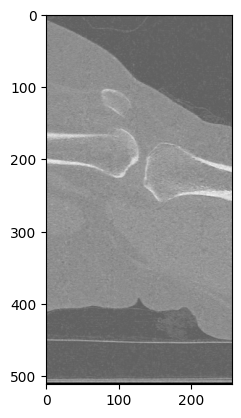

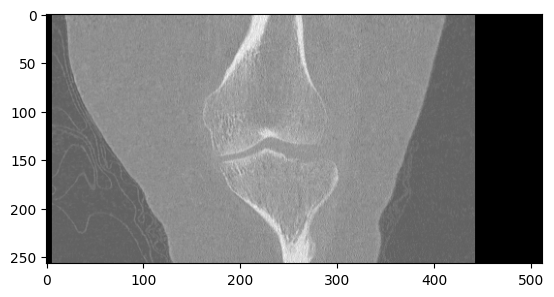

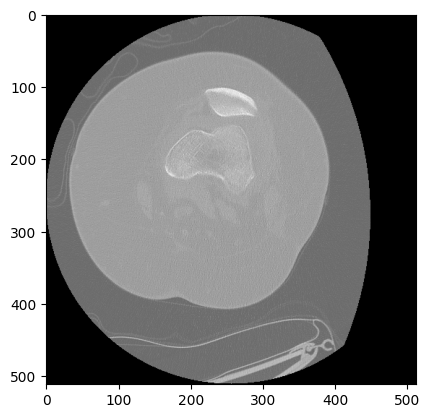

In [24]:
import os
from pathlib import Path
import dicom2nifti
import numpy as np
import nibabel as nib
from scipy import ndimage
import matplotlib.pyplot as plt
from totalsegmentator.python_api import totalsegmentator

data_dir = Path("DATA/")

for dir in os.listdir(data_dir):
    dicom_dir = os.path.join(data_dir, dir, 'DICOMS')
    nifti_file = os.path.join(data_dir, dir, dir + '_nifti.nii.gz')

    output_path = os.path.join(data_dir, dir, 'SEGS')
    
    if not os.path.exists(nifti_file):
        dicom2nifti.dicom_series_to_nifti(
            dicom_dir,
            nifti_file,
            reorient_nifti=True
        )

    img = nib.load(os.path.join(data_dir, dir, dir + '_nifti.nii.gz'))
    volume = img.get_fdata()

    if not os.path.exists(os.path.join(output_path, "femur_left.nii.gz")):
        totalsegmentator(dicom_dir, output_path, task='total', roi_subset=['femur_left'], quiet=True)
    if not os.path.exists(os.path.join(output_path, "tibia.nii.gz")):
        totalsegmentator(dicom_dir, output_path, task='appendicular_bones', quiet=True)

    femur = nib.load(os.path.join(output_path, 'femur_left.nii.gz')).get_fdata()

    femur_com = ndimage.center_of_mass(femur)
    print(femur_com)
    print(volume.shape)

    plt.figure()
    plt.imshow(np.rot90(volume[int(femur_com[0]), :, :], 2), cmap='gray')
    plt.figure()
    plt.imshow(np.rot90(volume[:, int(femur_com[1]), :]), cmap='gray')
    plt.figure()
    plt.imshow(np.rot90(volume[:, :, int(femur_com[2])]), cmap='gray')
    plt.show()

